In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    cross_val_score,
    KFold
)

from sklearn.metrics import mean_squared_error
from sklearn.dummy import DummyRegressor

sns.set_theme(style="whitegrid")

In [4]:
cwd = Path.cwd()

if (cwd / "data/processed/train_processed.csv").exists():
    project_dir = cwd
elif (cwd.parent / "data/processed/train_processed.csv").exists():
    project_dir = cwd.parent
else:
    raise FileNotFoundError("Cannot find processed data files")

train_data = pd.read_csv(
    project_dir / "data/processed/train_processed.csv"
)

test_data = pd.read_csv(
    project_dir / "data/processed/test_processed.csv"
)

print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)

display(train_data.head())

Train shape: (1458, 314)
Test shape: (1459, 313)


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_None,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,SalePrice
0,1,60,65.0,8450,7,5,2003,2003,196.0,706.0,...,0,0,1,0,0,0,0,1,0,208500
1,2,20,80.0,9600,6,8,1976,1976,0.0,978.0,...,0,0,1,0,0,0,0,1,0,181500
2,3,60,68.0,11250,7,5,2001,2002,162.0,486.0,...,0,0,1,0,0,0,0,1,0,223500
3,4,70,60.0,9550,7,5,1915,1970,0.0,216.0,...,0,0,1,1,0,0,0,0,0,140000
4,5,60,84.0,14260,8,5,2000,2000,350.0,655.0,...,0,0,1,0,0,0,0,1,0,250000


In [9]:
X = train_data.drop(columns=["Id", "SalePrice"])
y = np.log1p(train_data["SalePrice"])

X_test = test_data.drop(columns=["Id"])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)

print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

X shape: (1458, 312)
y shape: (1458,)
X_test shape: (1459, 312)
Missing values in X: 0
Missing values in X_test: 0


In [7]:
baseline_model = DummyRegressor(strategy="mean")

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_scores = cross_val_score(
    baseline_model,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

baseline_rmse = -baseline_scores.mean()

print("Baseline CV RMSE:", baseline_rmse)
print("Fold scores:", -baseline_scores)

Baseline CV RMSE: 0.399284908349551
Fold scores: [0.41059337 0.3887795  0.38084997 0.42653632 0.38966538]


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [12]:
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

In [13]:
linear_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

linear_rmse = -linear_scores.mean()

print("Linear Regression CV RMSE:", linear_rmse)
print("Fold scores:", -linear_scores)

Linear Regression CV RMSE: 0.13081729784745857
Fold scores: [0.13748533 0.14418496 0.12518553 0.14006289 0.10716779]


In [15]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "CV_RMSE": [baseline_rmse, linear_rmse]
})

display(comparison)

,Model,CV_RMSE
0,Baseline,0.399285
1,Linear Regression,0.130817


In [16]:
from sklearn.ensemble import RandomForestRegressor

In [18]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_features=0.7,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

In [19]:
rf_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

rf_rmse = -rf_scores.mean()

print("Random Forest CV RMSE:", rf_rmse)
print("Fold scores:", -rf_scores)

Random Forest CV RMSE: 0.1330503264477998
Fold scores: [0.14099075 0.12356692 0.1376491  0.13607783 0.12696703]


In [20]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "CV_RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
})

comparison = comparison.sort_values("CV_RMSE")

display(comparison)

,Model,CV_RMSE
1,Linear Regression,0.130817
2,Random Forest,0.133050
0,Baseline,0.399285


In [21]:
from sklearn.ensemble import GradientBoostingRegressor

In [22]:
gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

In [23]:
gb_scores = cross_val_score(
    gb_model,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

gb_rmse = -gb_scores.mean()

print("Gradient Boosting CV RMSE:", gb_rmse)
print("Fold scores:", -gb_scores)

Gradient Boosting CV RMSE: 0.12209350721776543
Fold scores: [0.12101446 0.11556315 0.12160976 0.13168888 0.12059128]


In [24]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "CV_RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse,
        gb_rmse
    ]
})

comparison = comparison.sort_values("CV_RMSE").reset_index(drop=True)

display(comparison)

,Model,CV_RMSE
0,Gradient Boosting,0.122094
1,Linear Regression,0.130817
2,Random Forest,0.133050
3,Baseline,0.399285


In [25]:
results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [26]:
from sklearn.model_selection import GridSearchCV

In [27]:
param_grid = {
    "n_estimators": [200, 300, 400],
    "learning_rate": [0.03, 0.05, 0.07],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [2, 3, 4]
}

In [28]:
grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [29]:
grid_search.fit(X, y)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV RMSE:")
print(-grid_search.best_score_)

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best parameters:
{'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 2, 'n_estimators': 400}

Best CV RMSE:
0.11905944707602645


In [30]:
best_model = grid_search.best_estimator_

print("Best model:", best_model)
print("Best GridSearchCV RMSE:", -grid_search.best_score_)

Best model: GradientBoostingRegressor(learning_rate=0.05, max_depth=2, min_samples_leaf=2,
                          n_estimators=400, random_state=42)
Best GridSearchCV RMSE: 0.11905944707602645


In [31]:
# Ուսուցանում ենք լավագույն մոդելը ամբողջ train տվյալների վրա
best_model.fit(X, y)

# Կանխատեսումներ ենք ստանում train տվյալների համար
train_predictions = best_model.predict(X)

# Հաշվում ենք RMSE-ն
train_rmse = np.sqrt(mean_squared_error(y, train_predictions))

print("Train RMSE:", train_rmse)
print("Cross-validation RMSE:", -grid_search.best_score_)

Train RMSE: 0.08497280078672136
Cross-validation RMSE: 0.11905944707602645


In [32]:
error_analysis = pd.DataFrame({
    "Actual": y,
    "Predicted": train_predictions
})

error_analysis["Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
)

error_analysis["Absolute_Error"] = error_analysis["Error"].abs()

display(
    error_analysis.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(10)
)

,Actual,Predicted,Error,Absolute_Error
631,11.320566,11.932387,-0.611821,0.611821
462,11.041064,11.649535,-0.608471,0.608471
1322,11.898195,12.440360,-0.542166,0.542166
969,11.813037,11.343735,0.469303,0.469303
1430,11.074436,11.521303,-0.446867,0.446867
410,11.002117,11.375749,-0.373632,0.373632
1451,11.344519,11.697512,-0.352993,0.352993
687,12.879020,12.553732,0.325288,0.325288
559,11.707678,12.021020,-0.313342,0.313342
680,11.979392,11.680673,0.298718,0.298718


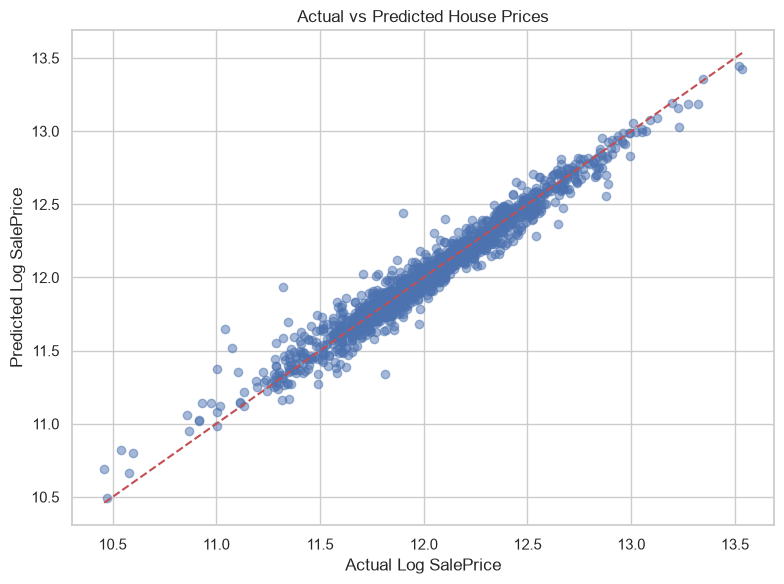

In [33]:
plt.figure(figsize=(8, 6))

plt.scatter(
    error_analysis["Actual"],
    error_analysis["Predicted"],
    alpha=0.5
)

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    "r--"
)

plt.xlabel("Actual Log SalePrice")
plt.ylabel("Predicted Log SalePrice")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()

plt.savefig(
    project_dir / "results/figures/actual_vs_predicted.png",
    dpi=300
)

plt.show()

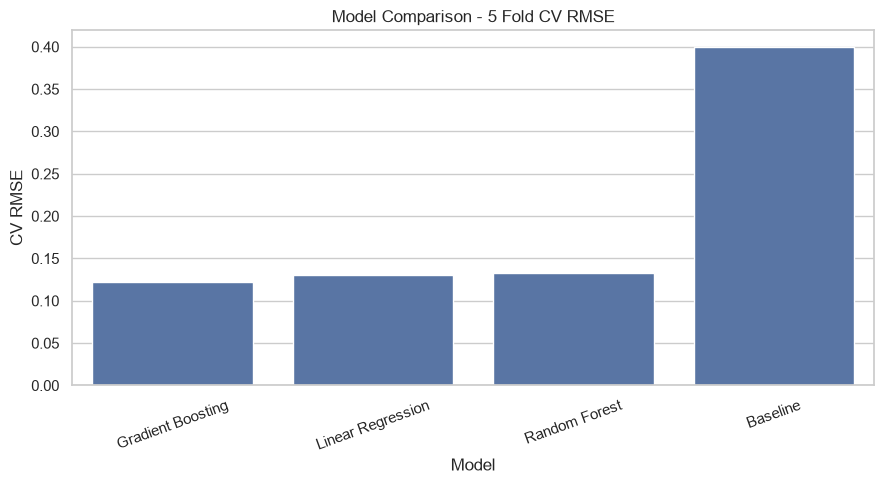

In [34]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="CV_RMSE"
)

plt.title("Model Comparison - 5 Fold CV RMSE")
plt.xlabel("Model")
plt.ylabel("CV RMSE")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    project_dir / "results/figures/model_comparison.png",
    dpi=300
)

plt.show()

In [35]:
comparison_final = pd.concat([
    comparison,
    pd.DataFrame({
        "Model": ["Tuned Gradient Boosting"],
        "CV_RMSE": [-grid_search.best_score_]
    })
], ignore_index=True)

comparison_final = (
    comparison_final
    .sort_values("CV_RMSE")
    .reset_index(drop=True)
)

display(comparison_final)

comparison_final.to_csv(
    project_dir / "results/model_comparison.csv",
    index=False
)

,Model,CV_RMSE
0,Tuned Gradient Boosting,0.119059
1,Gradient Boosting,0.122094
2,Linear Regression,0.130817
3,Random Forest,0.133050
4,Baseline,0.399285


In [36]:
# Կանխատեսում ենք log(SalePrice)-ը
test_predictions_log = best_model.predict(X_test)

# Վերադարձնում ենք սկզբնական գների սանդղակին
test_predictions = np.expm1(test_predictions_log)

print("First 10 predictions:")
print(test_predictions[:10])

print("Number of predictions:", len(test_predictions))

First 10 predictions:
[117486.6321513  163781.90397491 180471.27114064 188840.36539019
 192149.53015037 169887.34159723 179572.11411566 159106.12316353
 185469.26618684 122117.839502  ]
Number of predictions: 1459


In [42]:
submission = pd.DataFrame({
    "Id": test_data["Id"],
    "SalePrice": test_predictions
})

display(submission.head())

submission.to_csv(
    project_dir / "submissions/submission.csv",
    index=False
)

print("Submission saved successfully!")

,Id,SalePrice
0,1461,117486.632151
1,1462,163781.903975
2,1463,180471.271141
3,1464,188840.365390
4,1465,192149.530150


Submission saved successfully!


In [38]:
saved_submission = pd.read_csv(
    project_dir / "submissions/submission.csv"
)

print("Shape:", saved_submission.shape)
print("Missing values:", saved_submission.isnull().sum().sum())
print("Duplicate IDs:", saved_submission["Id"].duplicated().sum())
print(saved_submission.head())

Shape: (1459, 2)
Missing values: 0
Duplicate IDs: 0
     Id      SalePrice
0  1461  117486.632151
1  1462  163781.903975
2  1463  180471.271141
3  1464  188840.365390
4  1465  192149.530150
